# Counting Between Two Markers — RNN From Scratch

This notebook trains a simple recurrent neural network to count how many `0`s and `1`s appear strictly between two `7` markers in a sequence. Each sequence contains 30 random digits from `0` through `5`, plus two `7`s inserted at random positions. The progress bar reports batch progress, epoch duration, running average seconds per epoch, and train/validation MSE.

The network receives the original digit values (`0`–`7`) as a single scalar feature at each time step. The target is scaled to `[0, 1]` only for training; reported predictions are converted back to counts. The implementation uses PyTorch so Kaggle can run it on GPU when one is enabled.

In [28]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

SEED = 7
BASE_DIGITS = 30
SEQUENCE_LENGTH = BASE_DIGITS + 2
TRAIN_SAMPLES = 18000
VALIDATION_SAMPLES = 4500
BATCH_SIZE = 300
HIDDEN_SIZE = 32
EPOCHS = 60
LEARNING_RATE = 0.001
TARGET_SCALE = float(BASE_DIGITS)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print(f'Device: {DEVICE}')
print(f'Sequence length: {SEQUENCE_LENGTH} (30 digits + two markers)')

Device: cuda
Sequence length: 32 (30 digits + two markers)


## Dataset generation

The generator chooses 30 positions for ordinary digits in `0..5`, inserts exactly two `7`s into the resulting 32 positions, then counts only `0`s and `1`s strictly between the markers. The model input remains the raw sequence.

In [29]:
def create_dataset(sample_count, seed):
    rng = np.random.default_rng(seed)
    sequences = rng.integers(0, 6, size=(sample_count, SEQUENCE_LENGTH), dtype=np.int64)
    targets = np.empty(sample_count, dtype=np.float32)

    for i, sequence in enumerate(sequences):
        left, right = np.sort(rng.choice(SEQUENCE_LENGTH, size=2, replace=False))
        sequence[left] = sequence[right] = 7
        between = sequence[left + 1:right]
        targets[i] = np.count_nonzero((between == 0) | (between == 1))

    # Keep raw digit values as the single input feature.
    X = sequences.astype(np.float32)[..., None] / 7.0
    y = targets / TARGET_SCALE
    return (torch.tensor(X), torch.tensor(y[:, None]),
            torch.tensor(sequences), torch.tensor(targets))

X_train, y_train, raw_train, counts_train = create_dataset(TRAIN_SAMPLES, SEED)
X_val, y_val, raw_val, counts_val = create_dataset(VALIDATION_SAMPLES, SEED + 1)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
validation_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
print('Train:', tuple(X_train.shape), tuple(y_train.shape))
print('Validation:', tuple(X_val.shape), tuple(y_val.shape))
print('Example:', raw_train[0].tolist(), '→ count:', int(counts_train[0]))

Train: (18000, 32, 1) (18000, 1)
Validation: (4500, 32, 1) (4500, 1)
Example: [5, 3, 4, 7, 3, 4, 5, 1, 0, 1, 1, 5, 5, 0, 2, 4, 0, 4, 7, 2, 4, 1, 2, 1, 4, 1, 5, 2, 2, 3, 3, 3] → count: 6


## Network layers

The recurrent layer processes the sequence from left to right with a `tanh` hidden state. The dense layer reads the final hidden state and produces one continuous count estimate. There is no output activation.

In [30]:
class Layer(nn.Module):
    pass

class Rnn(Layer):
    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.input_weights = nn.Linear(input_size, hidden_size)
        self.hidden_weights = nn.Linear(hidden_size, hidden_size, bias=False)
        self.hidden_size = hidden_size

    def forward(self, sequence):
        batch_size = sequence.shape[0]
        hidden = sequence.new_zeros(batch_size, self.hidden_size)
        for step in range(sequence.shape[1]):
            hidden = torch.tanh(self.input_weights(sequence[:, step, :]) +
                                self.hidden_weights(hidden))
        return hidden

class Dense(Layer):
	def __init__(self, input_size, output_size):
		self.weights = np.random.randn(output_size, input_size) / np.sqrt(input_size)	# W matrix
		self.bias = np.zeros((output_size, 1))											# B vector

    def forward(self, inputs):
        return self.linear(inputs)

class MarkerCountingNetwork(nn.Module):
    def __init__(self, hidden_size):
        super().__init__()
        self.rnn = Rnn(input_size=1, hidden_size=hidden_size)
        self.output = Dense(hidden_size, 1)

    def forward(self, sequence):
        return self.output(self.rnn(sequence))

model = MarkerCountingNetwork(HIDDEN_SIZE).to(DEVICE)
print(model)

MarkerCountingNetwork(
  (rnn): Rnn(
    (input_weights): Linear(in_features=1, out_features=32, bias=True)
    (hidden_weights): Linear(in_features=32, out_features=32, bias=False)
  )
  (output): Dense(
    (linear): Linear(in_features=32, out_features=1, bias=True)
  )
)


## Training loop

Mean squared error is optimized on the scaled count. At each epoch, training and validation MSE are recorded in original count units so the curve has an intuitive scale.

In [31]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
history = {'train_mse': [], 'validation_mse': []}

@torch.no_grad()
def mse_in_count_units(X, y):
    model.eval()
    prediction = model(X.to(DEVICE))
    return torch.mean(((prediction - y.to(DEVICE)) * TARGET_SCALE) ** 2).item()

started = time.perf_counter()
epoch_durations = []
for epoch in range(1, EPOCHS + 1):
    epoch_started = time.perf_counter()
    model.train()
    train_loss_sum = 0.0
    train_examples = 0
    train_progress = tqdm(train_loader, desc=f'Epoch {epoch:02d}/{EPOCHS} | train',
                          unit='batch', leave=True, dynamic_ncols=True)
    for batch_X, batch_y in train_progress:
        batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(batch_X), batch_y)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * batch_y.size(0)
        train_examples += batch_y.size(0)
        train_progress.set_postfix(loss=f'{train_loss_sum / train_examples * TARGET_SCALE**2:.3f}',
                                   samples_s=f'{train_examples / max(time.perf_counter() - epoch_started, 1e-8):.0f}')

    train_mse = mse_in_count_units(X_train, y_train)
    model.eval()
    val_squared_error = 0.0
    val_examples = 0
    val_progress = tqdm(validation_loader, desc=f'Epoch {epoch:02d}/{EPOCHS} | validation',
                        unit='batch', leave=True, dynamic_ncols=True)
    with torch.no_grad():
        for batch_X, batch_y in val_progress:
            batch_X, batch_y = batch_X.to(DEVICE), batch_y.to(DEVICE)
            batch_error = ((model(batch_X) - batch_y) * TARGET_SCALE) ** 2
            val_squared_error += batch_error.sum().item()
            val_examples += batch_y.numel()
            val_progress.set_postfix(mse=f'{val_squared_error / val_examples:.3f}',
                                     samples_s=f'{val_examples / max(time.perf_counter() - epoch_started, 1e-8):.0f}')
    val_mse = val_squared_error / val_examples
    history['train_mse'].append(train_mse)
    history['validation_mse'].append(val_mse)
    epoch_durations.append(time.perf_counter() - epoch_started)
    print(f'  train MSE: {train_mse:.3f} | validation MSE: {val_mse:.3f} | '
          f'epoch: {epoch_durations[-1]:.1f}s | average epoch: {np.mean(epoch_durations):.1f}s')

print(f'Training time: {time.perf_counter() - started:.1f}s on {DEVICE}')

Epoch 01/60 | train:   0%|          | 0/60 [00:00<?, ?batch/s]

Epoch 01/60 | validation:   0%|          | 0/15 [00:00<?, ?batch/s]

  train MSE: 8.205 | validation MSE: 8.274 | epoch: 1.1s | average epoch: 1.1s


Epoch 02/60 | train:   0%|          | 0/60 [00:00<?, ?batch/s]

Epoch 02/60 | validation:   0%|          | 0/15 [00:00<?, ?batch/s]

  train MSE: 8.190 | validation MSE: 8.260 | epoch: 1.0s | average epoch: 1.0s


... (170 outputs left out)

  train MSE: 1.950 | validation MSE: 1.980 | epoch: 1.0s | average epoch: 1.0s


Epoch 60/60 | train:   0%|          | 0/60 [00:00<?, ?batch/s]

Epoch 60/60 | validation:   0%|          | 0/15 [00:00<?, ?batch/s]

  train MSE: 1.891 | validation MSE: 1.989 | epoch: 1.0s | average epoch: 1.0s
Training time: 59.5s on cuda


## Results

The plot compares training and validation MSE. The sample table shows raw input sequences, the true count, and the model estimate converted back from the scaled training output.

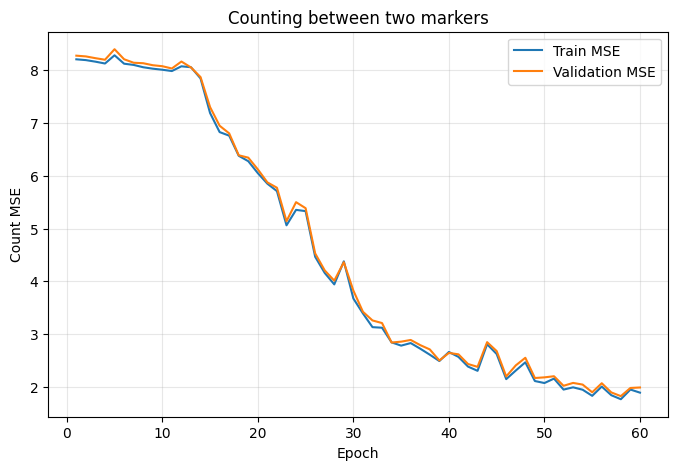

Validation examples:
expected= 0  predicted=  1.50  sequence=[4, 1, 1, 5, 1, 1, 3, 4, 3, 5, 0, 2, 3, 2, 2, 2, 0, 0, 3, 2, 5, 1, 5, 1, 0, 1, 2, 7, 7, 4, 4, 2]
expected= 0  predicted=  0.24  sequence=[0, 1, 2, 3, 2, 3, 2, 3, 0, 5, 3, 0, 4, 2, 5, 1, 5, 0, 2, 1, 2, 2, 5, 2, 4, 3, 7, 2, 7, 3, 2, 1]
expected=11  predicted=  8.34  sequence=[7, 0, 5, 1, 5, 0, 0, 2, 5, 2, 4, 4, 3, 5, 1, 0, 0, 5, 0, 4, 2, 5, 5, 0, 0, 2, 2, 3, 1, 4, 3, 7]
expected= 0  predicted=  0.23  sequence=[0, 2, 5, 1, 1, 2, 4, 3, 7, 3, 7, 4, 5, 1, 4, 3, 1, 0, 4, 3, 3, 2, 2, 0, 2, 1, 5, 0, 5, 2, 1, 2]
expected= 4  predicted=  5.44  sequence=[2, 2, 4, 0, 5, 4, 1, 1, 5, 1, 1, 5, 2, 3, 4, 7, 3, 3, 3, 1, 5, 0, 5, 1, 3, 2, 2, 1, 2, 2, 7, 5]
expected= 0  predicted=  1.96  sequence=[4, 4, 5, 1, 5, 1, 0, 4, 1, 5, 4, 3, 3, 1, 4, 2, 5, 0, 7, 2, 7, 5, 0, 1, 1, 2, 0, 3, 0, 5, 4, 3]
expected= 9  predicted= 10.06  sequence=[5, 7, 4, 3, 2, 1, 2, 0, 0, 4, 4, 2, 2, 5, 4, 1, 4, 0, 5, 3, 4, 4, 1, 5, 1, 3, 1, 0, 7, 3, 3, 2]
expected= 2  predict

In [32]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS + 1), history['train_mse'], label='Train MSE')
plt.plot(range(1, EPOCHS + 1), history['validation_mse'], label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Count MSE')
plt.title('Counting between two markers')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

model.eval()
with torch.no_grad():
    predictions = model(X_val.to(DEVICE)).cpu().squeeze(1).numpy() * TARGET_SCALE

print('Validation examples:')
for i in range(8):
    print(f'expected={int(counts_val[i]):2d}  predicted={predictions[i]:6.2f}  sequence={raw_val[i].tolist()}')